# Semiparametric Inference and Fluence Reporting for the 774 CE Miyake Event

This notebook demonstrates the end-to-end Bayesian inference workflow in `ticktack 2.0` on the audited 774–775 CE two-hemisphere tree-ring compilation (`775CE`) using the 22-box `Brehm21` carbon-box model. We combine a parametric cosmic-ray event pulse (`MiyakeSpike`) with analytically marginalized 11-year solar modulation (`HarmonicSolar`), causal Solin–Särkkä Gaussian-process background fluctuations (`GPProduction`), and hierarchical baseline $\Delta^{14}\mathrm{C}$ offsets, then sample the nonlinear spike posterior with `NumPyro` NUTS and report fluence under both pre-industrial and epoch-local $q_0$ conventions.

In [1]:
import math
import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import tinygp.kernels as tk
import ticktack as tt

cbm = tt.load_preset("Brehm21")
dataset = tt.load_bundled_event("775CE")
production = tt.ProductionSum(
    steady=tt.SteadyProduction(),
    solar=tt.HarmonicSolar.from_polar(amplitudes=0.0, phases=0.0),
    gp=tt.GPProduction(tk.quasisep.Matern32(scale=6.0, sigma=0.08), n_modes=32),
    spike=tt.MiyakeSpike(t_start=774.4, duration=0.35, fluence=6.5, profile="boxcar"),
)
model = tt.RadiocarbonModel(cbm, production)
print(f"ticktack {tt.__version__} | 775CE compilation: {dataset.n_series} series, {dataset.n_obs} rings")


ticktack 2.0.0a0 | 775CE compilation: 28 series, 313 rings


We parameterize the three nonlinear spike coordinates (`t_start`, `duration`, and `fluence`) via smooth unconstrained bijectors in `ParameterSpace` while `LinearMarginalConfig` analytically marginalizes the global Holocene offset $\Delta_{\mathrm{global}}$, all per-series laboratory offsets $\delta_{\mathrm{lab},s}$, the solar quadrature amplitudes, and the 32 causal GP modes. Eliminating the `ticktack 1.x` four-ring `mean(y[:4])` boundary clamp avoids secular ramp bias and allows `fit_map` (`BFGS`) to recover both the event parameters and the ambient epoch-local $\Delta^{14}\mathrm{C}_0$ baseline in closed form.

In [2]:
param_space = tt.ParameterSpace(model, [
    tt.ParamSpec("production.spike.t_start", "identity", prior_mean=774.4, prior_sd=0.4),
    tt.ParamSpec("production.spike.duration", "sigmoid", prior_mean=-1.0, prior_sd=1.2, low=0.05, high=2.0),
    tt.ParamSpec("production.spike.fluence", "exp", prior_mean=math.log(6.5), prior_sd=0.5),
])
cfg = tt.LinearMarginalConfig(
    offset_mode="hierarchical", solar_prior_sd=0.25, marginalize_solar=True, marginalize_gp=True,
)
map_res = tt.fit_map(model, dataset, param_space, cfg, method="BFGS", max_steps=150)
t_fine = jnp.linspace(769.0, 785.0, 240)
lp_nh = tt.linear_posterior(map_res.fitted_model, dataset, cfg, t_fine=t_fine, hemisphere="north")
lp_sh = tt.linear_posterior(map_res.fitted_model, dataset, cfg, t_fine=t_fine, hemisphere="south")
fl_map = float(map_res.theta_map["production.spike.fluence"])
q0_pi = float(tt.RadiocarbonModel.fluence_q0_years(fl_map))
q0_ep = float(tt.RadiocarbonModel.fluence_q0_years(fl_map, baseline_d14c_permil=lp_nh.baseline_d14c))
print(
    f"MAP t_start = {float(map_res.theta_map['production.spike.t_start']):.3f} CE | "
    f"duration = {float(map_res.theta_map['production.spike.duration']):.3f} yr\n"
    f"Fluence = {float(tt.RadiocarbonModel.fluence_atoms_cm2(fl_map)):.3e} atoms cm^-2 | "
    f"q0_PI = {q0_pi:.2f} yr | q0_epoch = {q0_ep:.2f} yr (Delta0 = {float(lp_nh.baseline_d14c):+.2f} permil)"
)


MAP t_start = 774.110 CE | duration = 1.175 yr
Fluence = 1.944e+08 atoms cm^-2 | q0_PI = 3.50 yr | q0_epoch = 3.58 yr (Delta0 = -21.73 permil)


Using `plot_d14c_fit` with `show_residuals=True`, we overlay the continuous Northern and Southern Hemisphere posterior mean $\Delta^{14}\mathrm{C}(t)$ trajectories (preserving `Brehm21`'s $\sim 4.4\text{‰}$ inter-hemispheric steady-state gradient and audited Austral summer growth windows) against all 28 tree-ring series. Passing `ring_pred=lp_nh.ring_pred_mean` incorporates each series' reconstructed hierarchical laboratory offset into the standardized pull residuals $(\mathrm{d} - \mathrm{m})/\sigma$ in the lower panel.

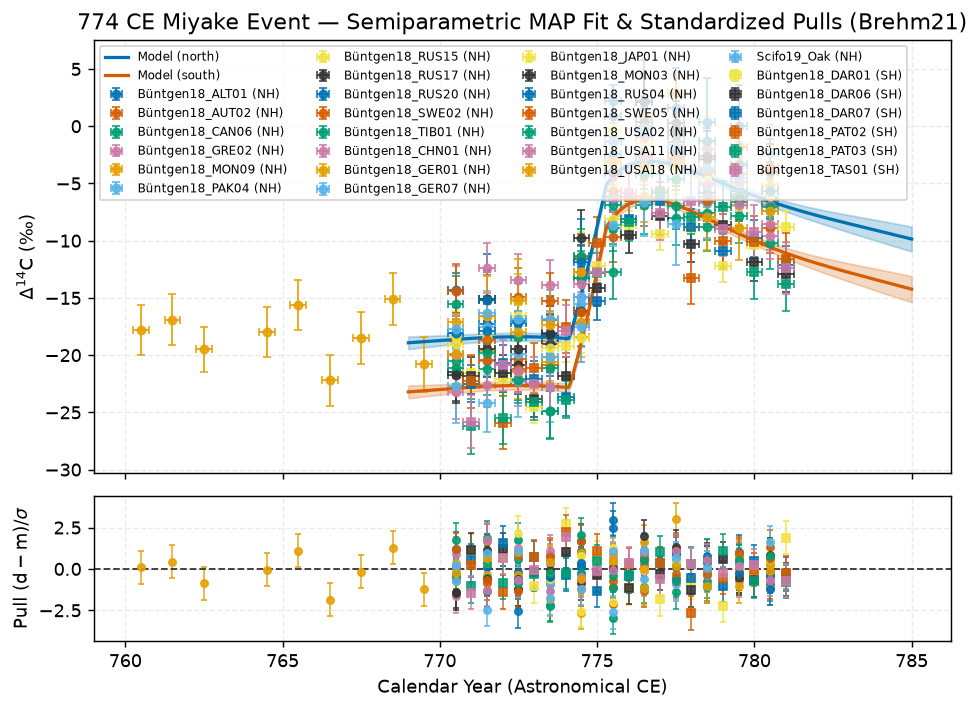

In [3]:
fig, axes = tt.plot_d14c_fit(
    dataset,
    t_fine=t_fine,
    d14c_pred={"north": lp_nh.d14c_fine_mean, "south": lp_sh.d14c_fine_mean},
    d14c_band={
        "north": (lp_nh.d14c_fine_mean - lp_nh.d14c_fine_std, lp_nh.d14c_fine_mean + lp_nh.d14c_fine_std),
        "south": (lp_sh.d14c_fine_mean - lp_sh.d14c_fine_std, lp_sh.d14c_fine_mean + lp_sh.d14c_fine_std),
    },
    ring_pred=lp_nh.ring_pred_mean,
    show_residuals=True,
    title="774 CE Miyake Event — Semiparametric MAP Fit & Standardized Pulls (Brehm21)",
)
axes[0].legend(ncol=4, fontsize=6.5, loc="upper left", frameon=True)
plt.show()


Next, we run `sample_nuts` across two chains in the collapsed 3D spike subspace with `reconstruct_linear=True`. At each posterior draw, `sample_nuts` samples exact conditional Gaussian realizations of the marginalized global and per-laboratory offsets so that epoch-local fluence uncertainty propagates both spike amplitude and baseline $\Delta^{14}\mathrm{C}_0$ covariance.

In [4]:
idata = tt.sample_nuts(
    map_res.fitted_model, dataset, param_space, cfg,
    num_warmup=80, num_samples=120, num_chains=2, max_tree_depth=6,
    init_map=False, reconstruct_linear=True, progress_bar=False,
    rng_key=jax.random.PRNGKey(7),
)
t_draws = np.asarray(idata.posterior["production__spike__t_start"]).ravel()
fl_draws = np.asarray(idata.posterior["production__spike__fluence"]).ravel()
d0_draws = np.asarray(idata.posterior["offset_global"]).ravel()
q0_pi_draws = np.asarray(tt.RadiocarbonModel.fluence_q0_years(fl_draws))
q0_ep_draws = np.asarray(tt.RadiocarbonModel.fluence_q0_years(fl_draws, baseline_d14c_permil=d0_draws))
rhat_vars = ["production__spike__t_start", "production__spike__duration", "production__spike__fluence"]
rhat_max = float(max(az.rhat(idata).data_vars[v].max() for v in rhat_vars))
print(
    f"NUTS (2x120 draws, max R-hat = {rhat_max:.3f}):\n"
    f"  t_start       = {np.median(t_draws):.3f} [{np.percentile(t_draws, 16):.3f}, {np.percentile(t_draws, 84):.3f}] CE\n"
    f"  q0 (pre-ind.) = {np.median(q0_pi_draws):.2f} [{np.percentile(q0_pi_draws, 16):.2f}, {np.percentile(q0_pi_draws, 84):.2f}] yr\n"
    f"  q0 (epoch)    = {np.median(q0_ep_draws):.2f} [{np.percentile(q0_ep_draws, 16):.2f}, {np.percentile(q0_ep_draws, 84):.2f}] yr"
)


NUTS (2x120 draws, max R-hat = 1.033):
  t_start       = 774.078 [773.947, 774.213] CE
  q0 (pre-ind.) = 3.50 [3.25, 3.82] yr
  q0 (epoch)    = 3.59 [3.32, 3.90] yr


Finally, we visualize the joint NUTS posterior over spike onset epoch $t_{\mathrm{start}}$ and epoch-local fluence $q_0(t_0)$ alongside the marginal offset between pre-industrial $q_{0,\mathrm{PI}}$ and epoch-local $q_0(t_0)$ induced by the ambient eighth-century $\Delta^{14}\mathrm{C}$ level.

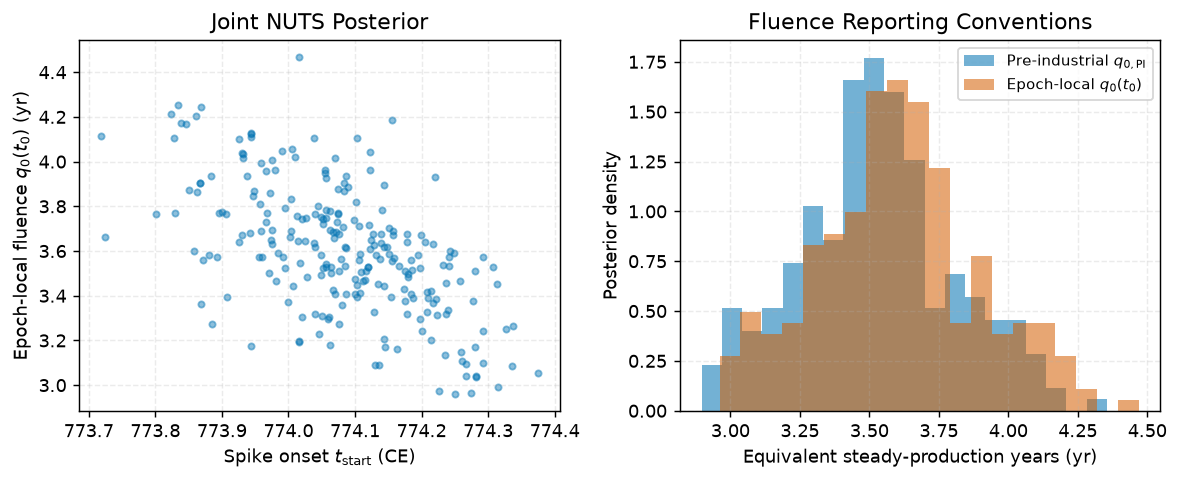

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.8))
axes[0].scatter(t_draws, q0_ep_draws, s=12, alpha=0.45, color="#0072B2")
axes[0].set(xlabel=r"Spike onset $t_{\mathrm{start}}$ (CE)", ylabel=r"Epoch-local fluence $q_0(t_0)$ (yr)", title="Joint NUTS Posterior")
axes[0].grid(True, alpha=0.25, ls="--")
axes[1].hist(q0_pi_draws, bins=20, density=True, alpha=0.55, color="#0072B2", label=r"Pre-industrial $q_{0,\mathrm{PI}}$")
axes[1].hist(q0_ep_draws, bins=20, density=True, alpha=0.55, color="#D55E00", label=r"Epoch-local $q_0(t_0)$")
axes[1].set(xlabel="Equivalent steady-production years (yr)", ylabel="Posterior density", title="Fluence Reporting Conventions")
axes[1].legend(frameon=True, fontsize=8.5)
axes[1].grid(True, alpha=0.25, ls="--")
fig.tight_layout()
plt.show()


Analytical marginalization of hierarchical baseline offsets, solar harmonics, and causal GP modes compresses a 60+ dimensional semiparametric radiocarbon model into a well-conditioned 3D nonlinear posterior that converges rapidly under both `BFGS` and `NumPyro` NUTS while preserving inter-hemispheric gradients and distinguishing pre-industrial from epoch-local $q_0$ fluence conventions.